<a href="https://colab.research.google.com/github/aayushikumar008-cloud/AayushiKumar_SynergyJTP/blob/main/Task_6/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("weatherAUS.csv")
print("Shape of Dataset:", df.shape)
print("\nDataset Info:")
df.info()

Shape of Dataset: (145460, 23)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-nu

In [91]:
print("Null Counts:")
for col in df.columns:
    null_count = df[col].isnull().sum()
    print(col, ":", null_count)

    if null_count > 50000:
        df = df.drop(columns=[col])

numeric_cols = [
'MinTemp', 'MaxTemp', 'Rainfall', 'WindGustSpeed',
    'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
    'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm']
df = df[numeric_cols]

for col in df.columns:
    df[col] = df[col].fillna(df[col].mean())

df.info()

Null Counts:
Date : 0
Location : 0
MinTemp : 1485
MaxTemp : 1261
Rainfall : 3261
Evaporation : 62790
Sunshine : 69835
WindGustDir : 10326
WindGustSpeed : 10263
WindDir9am : 10566
WindDir3pm : 4228
WindSpeed9am : 1767
WindSpeed3pm : 3062
Humidity9am : 2654
Humidity3pm : 4507
Pressure9am : 15065
Pressure3pm : 15028
Cloud9am : 55888
Cloud3pm : 59358
Temp9am : 1767
Temp3pm : 3609
RainToday : 3261
RainTomorrow : 3267
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 12 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   MinTemp        145460 non-null  float64
 1   MaxTemp        145460 non-null  float64
 2   Rainfall       145460 non-null  float64
 3   WindGustSpeed  145460 non-null  float64
 4   WindSpeed9am   145460 non-null  float64
 5   WindSpeed3pm   145460 non-null  float64
 6   Humidity9am    145460 non-null  float64
 7   Humidity3pm    145460 non-null  float64
 8   Pressure9am    145

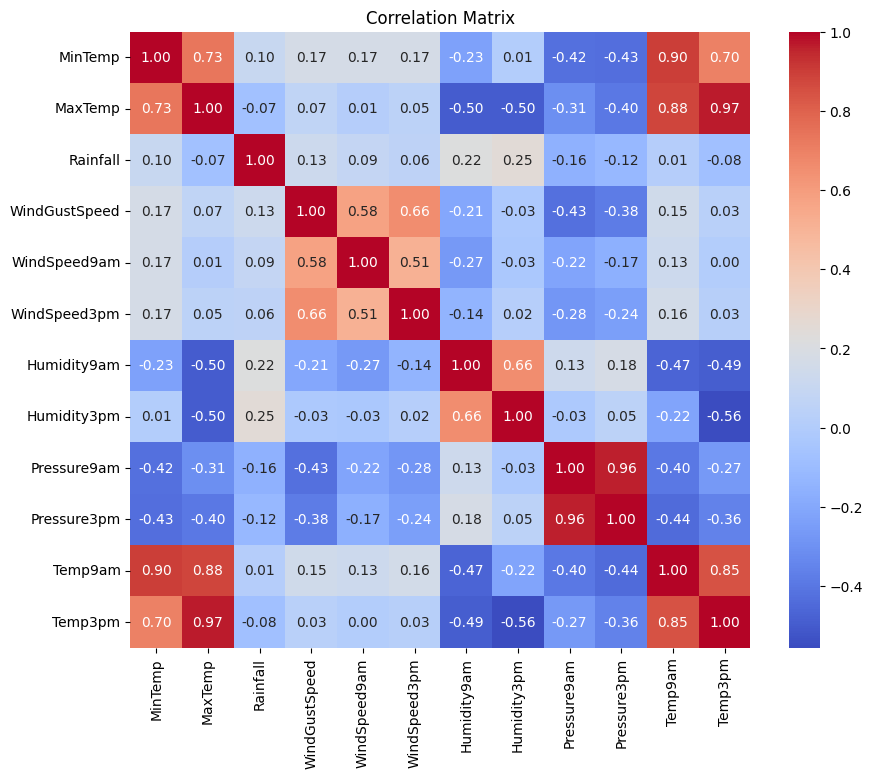

In [92]:
plt.figure(figsize=(10, 8))
correlation_matrix = df.corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [93]:
df = df.drop(columns=['Temp3pm', 'Pressure3pm'])


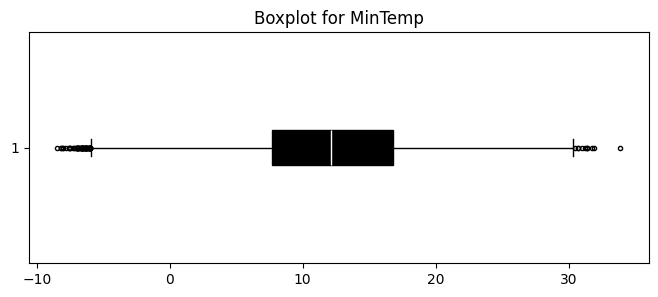

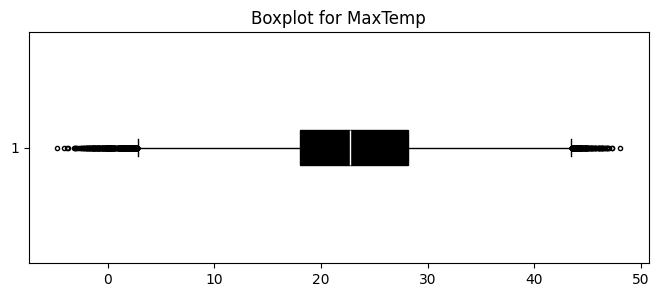

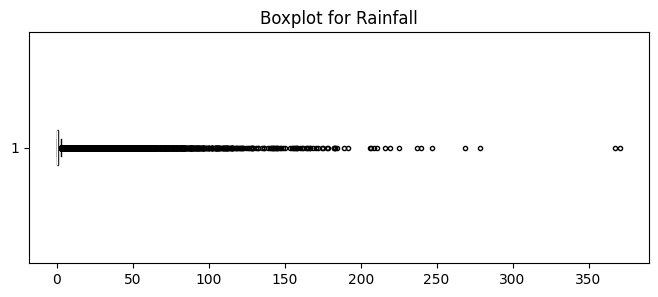

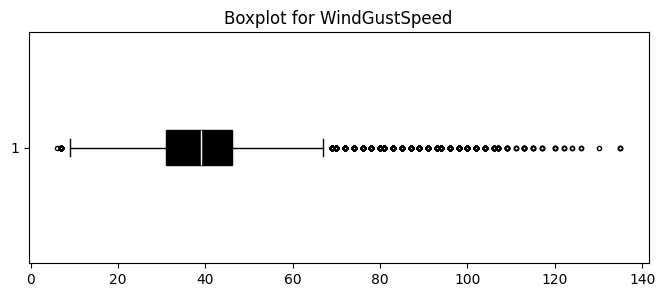

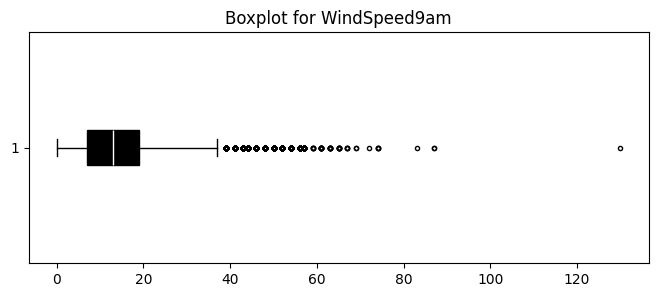

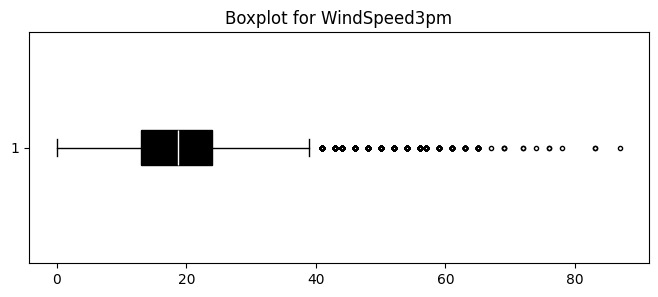

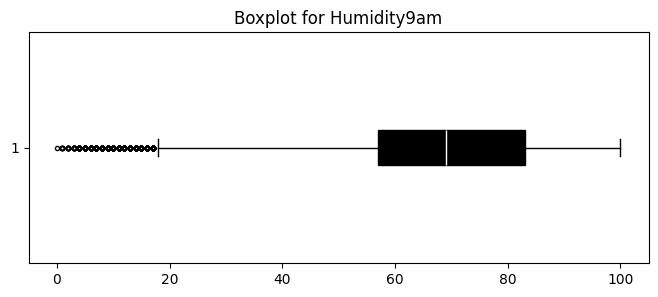

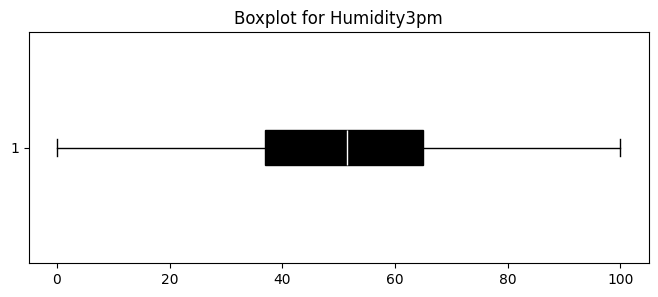

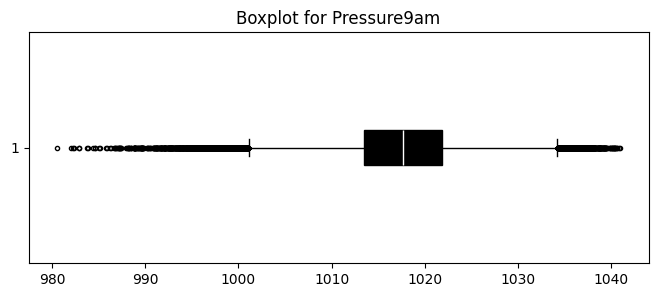

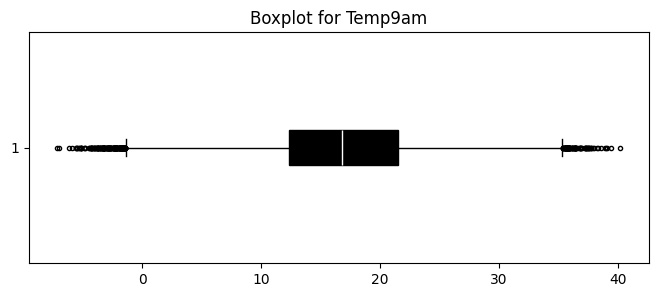

In [94]:
for col in df.columns:
    plt.figure(figsize=(8, 3))
    plt.boxplot(df[col].dropna(), vert=False, patch_artist=True,
                boxprops=dict(facecolor='black', color='black'),
                medianprops=dict(color='white'),
                flierprops=dict(marker='o', color='black', markersize=3))
    plt.title(f"Boxplot for {col}")
    plt.show()

In [95]:
from sklearn.model_selection import train_test_split

target = 'MaxTemp'
Y = df[target].values
X_df = df.drop(columns=[target])
X = X_df.values

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.25, random_state=42)

X_mean = np.mean(X_train, axis=0)
X_std = np.std(X_train, axis=0)

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

x, y = X_train_scaled.shape
weights = np.zeros(y)
bias = 0.0

learning_rate = 0.001
epochs =10001
cost_history = []

ss_total_train = np.sum((y_train - np.mean(y_train)) ** 2)
for i in range(epochs):
    y_pred = np.dot(X_train_scaled, weights) + bias
    error = y_pred - y_train
    cost = np.sum(error ** 2) / ss_total_train
    cost_history.append(cost)
    if i % 1000 == 0:
        print(f"Iteration {i}, Cost: {cost:.4f}")
    dw = (2 / x) * np.dot(X_train_scaled.T, error)
    db = (2 / x) * np.sum(error)
    weights -= learning_rate * dw
    bias -= learning_rate * db

y_test_pred = np.dot(X_test_scaled, weights) + bias

mae = np.mean(np.abs(y_test - y_test_pred))
mse = np.mean((y_test - y_test_pred) ** 2)
rmse = np.sqrt(mse)

print("Final Results ")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print("Learned Feature Weights ")
for a, w in zip(X_df.columns, weights):
    print(f"{a}: {w:.4f}")
print(f"Bias: {bias:.4f}")

Iteration 0, Cost: 11.7368
Iteration 1000, Cost: 0.3366
Iteration 2000, Cost: 0.1279
Iteration 3000, Cost: 0.1175
Iteration 4000, Cost: 0.1136
Iteration 5000, Cost: 0.1110
Iteration 6000, Cost: 0.1092
Iteration 7000, Cost: 0.1078
Iteration 8000, Cost: 0.1067
Iteration 9000, Cost: 0.1058
Iteration 10000, Cost: 0.1052
Final Results 
Mean Absolute Error (MAE): 1.7188
Root Mean Squared Error (RMSE): 2.2970
Learned Feature Weights 
MinTemp: 0.8952
Rainfall: -0.1178
WindGustSpeed: 0.1371
WindSpeed9am: -0.4734
WindSpeed3pm: -0.3099
Humidity9am: 1.0406
Humidity3pm: -3.0659
Pressure9am: -0.0845
Temp9am: 5.2451
Bias: 23.2133


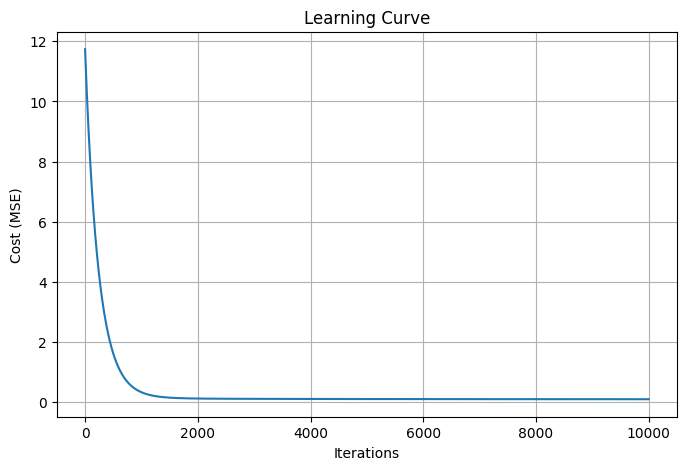

In [96]:
plt.figure(figsize=(8,5))

plt.plot(cost_history)

plt.xlabel("Iterations")
plt.ylabel("Cost (MSE)")
plt.title("Learning Curve")

plt.grid(True)

plt.show()

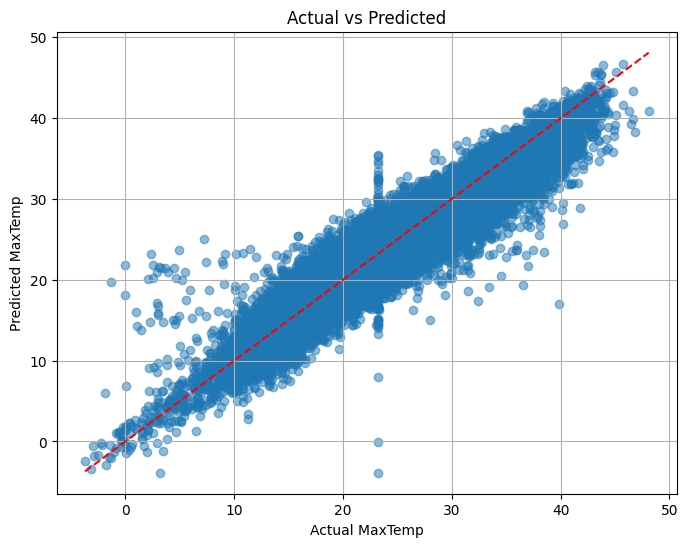

In [97]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual MaxTemp")
plt.ylabel("Predicted MaxTemp")
plt.title("Actual vs Predicted")

plt.grid(True)
plt.show()